In [3]:
#Importing the libraries
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import ols
import scipy as scipy

In [10]:
dataset = pd.read_csv('./datasets/Body_fat.csv')
dataset.head()

,Day,Gender,Weight,Chest,Abdomen,Hip,Thigh,Biceps,BodyFat
0,Monday,Male,154.25,93.1,85.2,94.5,59.0,32.0,12.3
1,Tuesday,Female,173.25,93.6,83.0,98.7,58.7,30.5,6.1
2,Wednesday,Female,154.00,95.8,87.9,99.2,59.6,28.8,25.3
3,Thursday,Male,184.75,101.8,86.4,101.2,60.1,32.4,10.4
4,Friday,Female,184.25,97.3,100.0,101.9,63.2,32.2,28.7


<Figure size 640x480 with 0 Axes>

d:\anaconda\Lib\site-packages\IPython\core\events.py:93: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  func(*args, **kwargs)
d:\anaconda\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


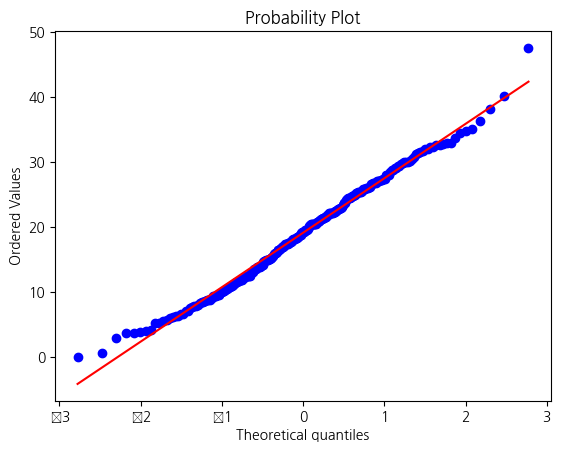

<Figure size 640x480 with 0 Axes>

In [11]:
#We need to check the normality of the data

#QQ-plot
stats.probplot(dataset.BodyFat, plot = plt)
plt.figure()

In [18]:
#Option 1: we check the normality of the data for the entire variable

stats.shapiro(dataset.BodyFat)

ShapiroResult(statistic=0.991894543170929, pvalue=0.18279968202114105)

In [19]:
#Option 2: we analyse the normality by categories

#We check the normality for east

stats.shapiro(dataset.BodyFat[dataset.Day == 'Monday'])

ShapiroResult(statistic=0.9688053727149963, pvalue=0.8189046382904053)

In [20]:
#We check the normality for south

stats.shapiro(dataset.BodyFat[dataset.Day == 'Tuesday'])

ShapiroResult(statistic=0.9423207640647888, pvalue=0.3784196674823761)

In [21]:
#We check the normality for north

stats.shapiro(dataset.BodyFat[dataset.Day == 'Thursday'])

ShapiroResult(statistic=0.9766784906387329, pvalue=0.19423650205135345)

In [22]:
dataset.Day.unique()

array(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'],
      dtype=object)

In [24]:
#We create variables per region

monday = dataset.BodyFat[dataset.Day == 'Monday']
tuesday = dataset.BodyFat[dataset.Day == 'Tuesday']
wednesday = dataset.BodyFat[dataset.Day == 'Wednesday']
thursday = dataset.BodyFat[dataset.Day == 'Thursday']
friday = dataset.BodyFat[dataset.Day == 'Friday']
saturday = dataset.BodyFat[dataset.Day == 'Saturday']

In [25]:
from scipy.stats import levene

In [30]:
levene(monday,tuesday,wednesday,thursday,friday,saturday, center = 'mean')

LeveneResult(statistic=1.5409903341457776, pvalue=0.17768652309090702)

In [29]:
#model = ols('X ~ categorical variable', data = df)
model = ols('BodyFat~Day', data = dataset).fit()
aov = sm.stats.anova_lm(model, type= 2)
aov

,df,sum_sq,mean_sq,F,PR(>F)
Day,5.0,103.893554,20.778711,0.294594,0.915649
Residual,245.0,17280.678637,70.533382,NaN,NaN
